# P2 · Ingeniería de Hábitos + Yeo-Johnson + StandardScaler

**P2** es una de las tres metodologías de preprocesamiento de la matriz 3×3 (P1/P2/P3 × M1 Random Forest / M2 XGBoost / M3 MLP). Se aplica sobre el **benchmark preventivo** (17 variables, sin `Weight`, `Height` ni `IMC`) y hace tres cosas:

1. **Corrige la asimetría** de las variables no binarias con la transformación **Yeo-Johnson** (admite ceros, a diferencia de Box-Cox).
2. **Agrega 4 variables de dominio** construidas solo con hábitos (sin peso ni estatura): `Balance_Act_Sed`, `Hidratacion_Activa`, `Riesgo_Gen_Cal` e `Indice_Protector`.
3. **Escala las 21 variables** resultantes a media 0 y desviación 1.

**¿Por qué?** A los árboles (M1, M2) los ratios directos les ahorran cortes: una relación como "actividad física frente a pantallas" necesitaría varios splits para aproximarse con las variables originales. A la red neuronal (M3) le entrega entradas simétricas y en la misma escala, lo que estabiliza el descenso de gradiente.

Todo vive en `src/p2_habitos.py` como un `Pipeline` de sklearn, de modo que se **ajusta solo con entrenamiento**.

## 1. Configuración

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew, spearmanr
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# Permite importar src/ al ejecutar el notebook desde la raíz del repositorio
raiz = Path.cwd()
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.p2_habitos import HABIT_FEATURES, agregar_habitos, columnas_continuas, construir_p2

SEMILLA = 20
AZUL, NARANJA = "#2a78d6", "#eb6834"   # antes / después (P1 / P2)
pd.set_option("display.precision", 3)

## 2. Datos: mismo contrato que `Desarrollo.ipynb`

Se replica exactamente la carga, la codificación, la eliminación de duplicados y la partición 80/20 estratificada con `SEMILLA = 20`, para que P2 se compare en las mismas filas que P1 y P3.

In [2]:
from ucimlrepo import fetch_ucirepo

obesidad = fetch_ucirepo(id=544)
X = obesidad.data.features
y = obesidad.data.targets
dataset = pd.concat([X, y], axis=1)
dataset["IMC"] = dataset["Weight"] / dataset["Height"] ** 2
print("Dimensiones:", dataset.shape)

Dimensiones: (2111, 18)


In [3]:
data = dataset.copy()

# Binarias
data["Gender"] = data["Gender"].map({"Female": 0, "Male": 1})
for col in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    data[col] = data[col].map({"no": 0, "yes": 1})

# Ordinales
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    data[col] = data[col].round().astype(int)

orden_frecuencia = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
data["CAEC"] = data["CAEC"].map(orden_frecuencia)
data["CALC"] = data["CALC"].replace("Always", "Frequently")   # "Always" tiene 1 solo registro
data["CALC"] = data["CALC"].map(orden_frecuencia)

# Nominales
data["MTRANS"] = data["MTRANS"].replace({"Bike": "Two_Wheels", "Motorbike": "Two_Wheels"})
data = pd.get_dummies(data, columns=["MTRANS"], prefix="MTRANS", dtype=int)

# Target ordinal de 0 a 6
niveles = {
    "Insufficient_Weight": 0, "Normal_Weight": 1, "Overweight_Level_I": 2, "Overweight_Level_II": 3,
    "Obesity_Type_I": 4, "Obesity_Type_II": 5, "Obesity_Type_III": 6,
}
data["NObeyesdad"] = data["NObeyesdad"].map(niveles)
nombres_clases = {v: k for k, v in niveles.items()}

# Duplicados: se eliminan ANTES de dividir
sin_dup = ~dataset.duplicated()
print(f"Duplicados eliminados: {(~sin_dup).sum()} ({len(dataset)} -> {sin_dup.sum()} registros)")
data_u = data[sin_dup]

excluir = ["NObeyesdad"]
X_prev = data_u.drop(columns=excluir + ["Weight", "Height", "IMC"])   # benchmark preventivo
X_oper = data_u.drop(columns=excluir)                                 # benchmark operativo (referencia)
y = data_u["NObeyesdad"]

idx_train, idx_test = train_test_split(y.index, test_size=0.2, stratify=y, random_state=SEMILLA)
X_train, X_test = X_prev.loc[idx_train], X_prev.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

assert not {"NObeyesdad", "Weight", "Height", "IMC"} & set(X_train.columns), "Fuga en el preventivo"
print("Preventivo -> Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Duplicados eliminados: 24 (2111 -> 2087 registros)
Preventivo -> Entrenamiento: (1669, 17) | Prueba: (418, 17)


## 3. Definición de P2

In [4]:
p2 = construir_p2(X_train).set_output(transform="pandas")
p2.fit(X_train)
X_train_p2 = p2.transform(X_train)
X_test_p2 = p2.transform(X_test)

continuas = columnas_continuas(agregar_habitos(X_train))
print(f"Variables de salida: {X_train_p2.shape[1]}")
print(f"Con Yeo-Johnson ({len(continuas)}): {continuas}")
print(f"Solo StandardScaler ({X_train_p2.shape[1] - len(continuas)}): "
      f"{[c for c in X_train_p2.columns if c not in continuas]}")
p2

Variables de salida: 21
Con Yeo-Johnson (11): ['Age', 'FCVC', 'NCP', 'CAEC', 'CH2O', 'FAF', 'TUE', 'CALC', 'Balance_Act_Sed', 'Hidratacion_Activa', 'Indice_Protector']
Solo StandardScaler (10): ['Gender', 'family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC', 'MTRANS_Automobile', 'MTRANS_Public_Transportation', 'MTRANS_Two_Wheels', 'MTRANS_Walking', 'Riesgo_Gen_Cal']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('habitos', ...), ('transformacion', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Gender','Age','family_history_with_overweight',..., 'MTRANS_Public_Transportation','MTRANS_Two_Wheels','MTRANS_Walking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function agr...0027B5FC9A090>
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",<function _no...0027B5FC9A140>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The defa

### Las 4 variables de hábitos

| Variable | Fórmula | Qué mide | Relación esperada con la obesidad |
|---|---|---|---|
| `Balance_Act_Sed` | `FAF / (TUE + 1)` | Actividad física frente al tiempo en pantallas (el +1 evita dividir por 0) | Negativa: más actividad relativa al sedentarismo, menor nivel |
| `Hidratacion_Activa` | `CH2O * (FAF + 1)` | Consumo de agua potenciado por la actividad física | Negativa: hidratación ligada a un estilo de vida activo |
| `Riesgo_Gen_Cal` | `family_history_with_overweight * FAVC` | Antecedente familiar **y** consumo frecuente de comida calórica a la vez (interacción) | Positiva: combina predisposición genética y dieta |
| `Indice_Protector` | `FCVC + CH2O + FAF + SCC - FAVC` | Suma de hábitos protectores (verduras, agua, ejercicio, control de calorías) menos la comida calórica | Negativa: más hábitos protectores, menor nivel |

> **Nota:** la fórmula original de `Indice_Protector` llegó truncada; los signos usados (todos `+` salvo `-FAVC`) son un **supuesto pendiente de confirmar con Sebastián**. Además, al ser una combinación lineal exacta de sus componentes, no aporta información nueva a un modelo lineal; su valor está en darle a los árboles un resumen en un solo corte.

Ninguna variable usa `Weight`, `Height` ni `IMC`: se calculan fila a fila con hábitos, sin parámetros aprendidos, así que no pueden filtrar información de prueba.

## 4. Verificación de fuga de información

### 4.1 Ninguna variable usada deriva de peso o estatura

In [5]:
prohibidas = {"Weight", "Height", "IMC"}
assert not prohibidas & set(X_train_p2.columns)
assert not prohibidas & set(p2.get_feature_names_out())
print("Columnas de P2 sin Weight/Height/IMC: OK")

for col in sorted(prohibidas):
    try:
        agregar_habitos(X_oper.loc[idx_train].drop(columns=list(prohibidas - {col})))
        print(f"{col}: NO se rechazó (¡revisar!)")
    except ValueError as e:
        print(f"{col}: rechazada -> {e}")

Columnas de P2 sin Weight/Height/IMC: OK
Height: rechazada -> P2 no admite variables antropométricas (fuga de la clase): ['Height']
IMC: rechazada -> P2 no admite variables antropométricas (fuga de la clase): ['IMC']
Weight: rechazada -> P2 no admite variables antropométricas (fuga de la clase): ['Weight']


### 4.2 ¿Las variables nuevas permiten reconstruir el IMC?

Si las 4 variables nuevas escondieran información del peso, una regresión lineal predeciría mejor el IMC con las 21 variables de P2 que con las 17 originales. Se ajusta en entrenamiento y se mide R² en prueba.

In [6]:
imc_train, imc_test = data_u.loc[idx_train, "IMC"], data_u.loc[idx_test, "IMC"]

r2_17 = r2_score(imc_test, LinearRegression().fit(X_train, imc_train).predict(X_test))
r2_21 = r2_score(imc_test, LinearRegression().fit(X_train_p2, imc_train).predict(X_test_p2))
pd.DataFrame({"R² (prueba) prediciendo IMC": [r2_17, r2_21]},
             index=["17 variables originales", "21 variables de P2"])

,R² (prueba) prediciendo IMC
17 variables originales,0.411
21 variables de P2,0.439


### 4.3 Correlación de Spearman de cada variable nueva con la clase (entrenamiento)

In [7]:
habitos_train = agregar_habitos(X_train)[HABIT_FEATURES]
spearman = pd.DataFrame(
    [spearmanr(habitos_train[c], y_train) for c in HABIT_FEATURES],
    index=HABIT_FEATURES, columns=["rho de Spearman", "p-valor"])
spearman

,rho de Spearman,p-valor
Balance_Act_Sed,-0.162,2.533e-11
Hidratacion_Activa,-0.055,2.337e-02
Riesgo_Gen_Cal,0.520,2.218e-116
Indice_Protector,-0.025,3.131e-01


### 4.4 Contraejemplo: por qué la hidratación NO se divide por el peso

Una alternativa natural sería `CH2O / Weight` (agua por kilo). **No forma parte de P2**: se muestra solo como contraejemplo. Como el peso define la clase, esa variable introduce fuga. Se compara el F1-macro en prueba de XGBoost con las 17 variables originales más cada versión de la hidratación.

In [8]:
def xgb_contraejemplo():
    return XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.1,
                         random_state=SEMILLA, eval_metric="mlogloss")

peso = data_u["Weight"]
variantes = {
    "17 originales (sin hidratación)": (X_train, X_test),
    "+ CH2O*(FAF+1)  [usada en P2]": (
        X_train.assign(Hidratacion=X_train["CH2O"] * (X_train["FAF"] + 1)),
        X_test.assign(Hidratacion=X_test["CH2O"] * (X_test["FAF"] + 1))),
    "+ CH2O/Weight  [CONTRAEJEMPLO con fuga]": (
        X_train.assign(Hidratacion=X_train["CH2O"] / peso.loc[idx_train]),
        X_test.assign(Hidratacion=X_test["CH2O"] / peso.loc[idx_test])),
}
filas = {}
for nombre, (Xtr, Xte) in variantes.items():
    pred = xgb_contraejemplo().fit(Xtr, y_train).predict(Xte)
    rho = spearmanr(Xtr["Hidratacion"], y_train)[0] if "Hidratacion" in Xtr else np.nan
    filas[nombre] = {"F1-macro prueba": f1_score(y_test, pred, average="macro"),
                     "Spearman con la clase (train)": rho}
pd.DataFrame(filas).T

,F1-macro prueba,Spearman con la clase (train)
17 originales (sin hidratación),0.791,NaN
+ CH2O*(FAF+1) [usada en P2],0.801,-0.055
+ CH2O/Weight [CONTRAEJEMPLO con fuga],0.890,-0.529


## 5. Efecto de Yeo-Johnson

Asimetría (coeficiente de skewness) de cada variable continua en entrenamiento, antes (datos codificados + hábitos) y después de P2.

In [9]:
crudo_train = agregar_habitos(X_train)
yj = p2.named_steps["transformacion"].named_transformers_["yeo_johnson"]

tabla_asimetria = pd.DataFrame({
    "Asimetría antes": [skew(crudo_train[c]) for c in continuas],
    "Asimetría después": [skew(X_train_p2[c]) for c in continuas],
    "Lambda Yeo-Johnson": yj.lambdas_,
}, index=continuas)
tabla_asimetria["|antes| - |después|"] = (tabla_asimetria["Asimetría antes"].abs()
                                         - tabla_asimetria["Asimetría después"].abs())
tabla_asimetria.sort_values("Asimetría antes", key=abs, ascending=False)

,Asimetría antes,Asimetría después,Lambda Yeo-Johnson,|antes| - |después|
CAEC,2.057,-0.156,-0.380,1.901
Age,1.466,0.087,-1.567,1.379
NCP,-1.085,-0.091,2.687,0.994
Balance_Act_Sed,1.041,0.071,-0.462,0.970
Hidratacion_Activa,1.005,0.005,-0.039,1.000
TUE,0.519,0.051,-0.237,0.468
FAF,0.452,-0.033,0.161,0.420
FCVC,-0.435,-0.169,2.111,0.266
Indice_Protector,0.299,-0.011,0.574,0.288
CALC,-0.248,-0.108,1.219,0.140


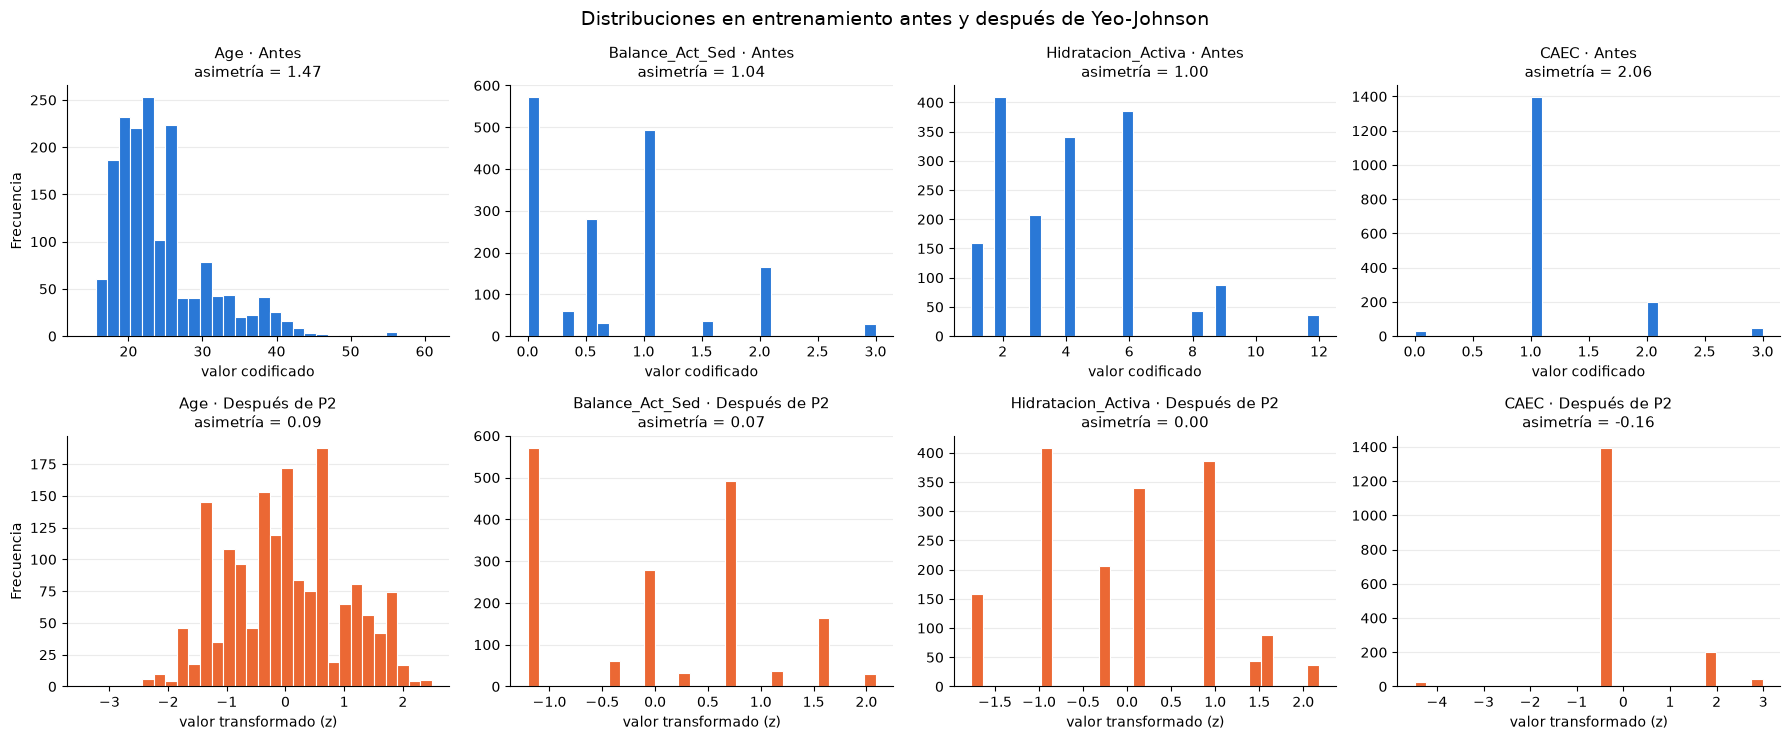

In [10]:
# Las 3 variables pedidas + la más asimétrica entre las restantes
fijas = ["Age", "Balance_Act_Sed", "Hidratacion_Activa"]
resto = tabla_asimetria.drop(index=fijas)
cuarta = resto["Asimetría antes"].abs().idxmax()
graficar = fijas + [cuarta]

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for j, col in enumerate(graficar):
    for i, (serie, color, etapa) in enumerate([(crudo_train[col], AZUL, "Antes"),
                                                (X_train_p2[col], NARANJA, "Después de P2")]):
        ax = axes[i, j]
        ax.hist(serie, bins=30, color=color, edgecolor="white", linewidth=0.8)
        ax.set_title(f"{col} · {etapa}\nasimetría = {skew(serie):.2f}", fontsize=11)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)
    axes[0, j].set_xlabel("valor codificado")
    axes[1, j].set_xlabel("valor transformado (z)")
axes[0, 0].set_ylabel("Frecuencia")
axes[1, 0].set_ylabel("Frecuencia")
fig.suptitle("Distribuciones en entrenamiento antes y después de Yeo-Johnson", fontsize=14)
plt.tight_layout()
plt.show()

## 6. Ajuste solo con entrenamiento

Los lambdas de Yeo-Johnson y las medias/desviaciones son parámetros **aprendidos**. Si se ajustaran con todos los datos, la información de prueba se colaría en el preprocesamiento. El `Pipeline` lo evita: se ajusta con `X_train` y solo transforma `X_test`.

In [11]:
p2_todo = construir_p2(X_train).fit(X_prev)   # INCORRECTO a propósito: incluye prueba
lambdas = pd.DataFrame({
    "lambda (solo train)": yj.lambdas_,
    "lambda (train + test)": p2_todo.named_steps["transformacion"].named_transformers_["yeo_johnson"].lambdas_,
}, index=continuas)
lambdas["diferencia"] = lambdas["lambda (train + test)"] - lambdas["lambda (solo train)"]
lambdas

,lambda (solo train),lambda (train + test),diferencia
Age,-1.567,-1.623,-5.599e-02
FCVC,2.111,2.116,4.852e-03
NCP,2.687,2.696,9.479e-03
CAEC,-0.380,-0.329,5.174e-02
CH2O,0.924,0.877,-4.685e-02
FAF,0.161,0.157,-4.343e-03
TUE,-0.237,-0.210,2.639e-02
CALC,1.219,1.236,1.729e-02
Balance_Act_Sed,-0.462,-0.467,-5.532e-03
Hidratacion_Activa,-0.039,-0.045,-5.897e-03


In [12]:
resumen = pd.DataFrame({
    "media train": X_train_p2.mean(), "desv. train": X_train_p2.std(ddof=0),
    "media test": X_test_p2.mean(), "desv. test": X_test_p2.std(ddof=0),
})
print(f"Train: |media| máx = {resumen['media train'].abs().max():.2e}, "
      f"desv. en [{resumen['desv. train'].min():.4f}, {resumen['desv. train'].max():.4f}]")
print(f"Test:  |media| máx = {resumen['media test'].abs().max():.3f}, "
      f"desv. en [{resumen['desv. test'].min():.3f}, {resumen['desv. test'].max():.3f}]  "
      "(no exactamente 0/1: es lo esperado)")
resumen

Train: |media| máx = 1.74e-14, desv. en [1.0000, 1.0000]
Test:  |media| máx = 0.118, desv. en [0.828, 1.082]  (no exactamente 0/1: es lo esperado)


,media train,desv. train,media test,desv. test
Age,-1.736e-14,1.0,-0.044,0.988
FCVC,-1.118e-17,1.0,-0.036,1.022
NCP,4.321e-16,1.0,0.051,0.993
CAEC,9.749e-16,1.0,-0.117,0.946
CH2O,5.939e-16,1.0,-0.118,1.011
FAF,-5.960e-17,1.0,0.061,1.049
TUE,-2.107e-16,1.0,0.065,1.019
CALC,9.792e-17,1.0,0.047,0.988
Balance_Act_Sed,-3.725e-17,1.0,0.029,1.019
Hidratacion_Activa,-1.022e-16,1.0,-0.021,1.066


## 7. Impacto en los 3 modelos (sin ajuste de hiperparámetros)

Comparación orientativa de P1 (`RobustScaler` sobre las 17 variables) frente a P2, con parámetros por defecto razonables. El ajuste fino corresponde a cada responsable de modelo. Se usa **validación cruzada estratificada de 5 particiones solo sobre entrenamiento**: la prueba queda reservada para la evaluación final.

In [13]:
def modelos():
    return {
        "M1 Random Forest": RandomForestClassifier(n_estimators=400, random_state=SEMILLA, n_jobs=-1),
        "M2 XGBoost": XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.1, subsample=0.9,
                                    colsample_bytree=0.9, random_state=SEMILLA, eval_metric="mlogloss"),
        "M3 MLP": MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=500,
                                random_state=SEMILLA),
    }

preprocesos = {
    "P1 (RobustScaler, 17)": lambda: Pipeline([("escala", RobustScaler())]),
    "P2 (hábitos + YJ, 21)": lambda: construir_p2(X_train),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

filas = []
for nombre_m, modelo in modelos().items():
    for nombre_p, preproceso in preprocesos.items():
        pipe = Pipeline([("pre", preproceso()), ("modelo", modelo)])
        f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")
        filas.append({"Modelo": nombre_m, "Preproceso": nombre_p, "F1 media": f1.mean(), "F1 desv.": f1.std()})

cv_resultados = pd.DataFrame(filas)
tabla_cv = cv_resultados.pivot(index="Modelo", columns="Preproceso", values=["F1 media", "F1 desv."])
tabla_cv

F1 media                        \
Preproceso       P1 (RobustScaler, 17) P2 (hábitos + YJ, 21)   
Modelo                                                         
M1 Random Forest                 0.795                 0.777   
M2 XGBoost                       0.780                 0.789   
M3 MLP                           0.509                 0.565   

                              F1 desv.                        
Preproceso       P1 (RobustScaler, 17) P2 (hábitos + YJ, 21)  
Modelo                                                        
M1 Random Forest                 0.015                 0.009  
M2 XGBoost                       0.014                 0.014  
M3 MLP                           0.072                 0.031

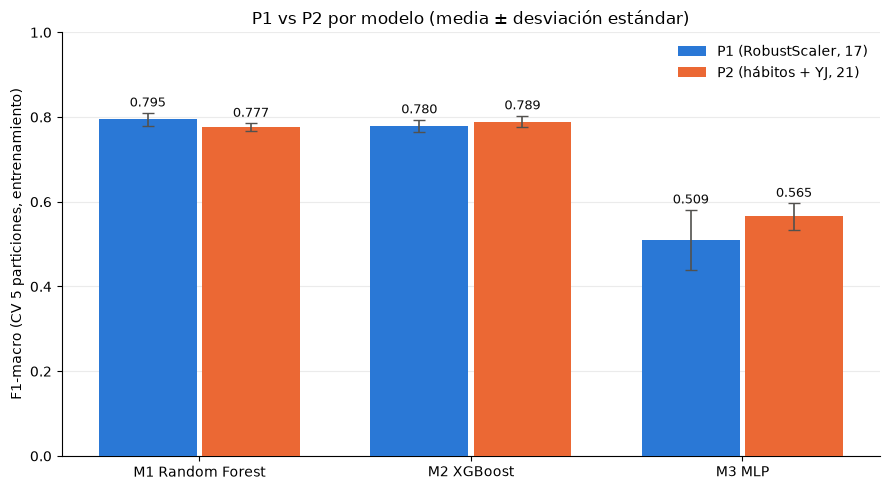

In [14]:
modelos_orden = cv_resultados["Modelo"].unique()
x = np.arange(len(modelos_orden))
ancho = 0.36

fig, ax = plt.subplots(figsize=(9, 5))
for k, (nombre_p, color) in enumerate(zip(preprocesos, [AZUL, NARANJA])):
    sub = cv_resultados[cv_resultados["Preproceso"] == nombre_p].set_index("Modelo").loc[modelos_orden]
    pos = x + (k - 0.5) * (ancho + 0.02)
    ax.bar(pos, sub["F1 media"], width=ancho, color=color, label=nombre_p, zorder=3)
    ax.errorbar(pos, sub["F1 media"], yerr=sub["F1 desv."], fmt="none", ecolor="#52514e",
                capsize=4, linewidth=1.2, zorder=4)
    for p_, v, d in zip(pos, sub["F1 media"], sub["F1 desv."]):
        ax.text(p_, v + d + 0.015, f"{v:.3f}", ha="center", fontsize=9, color="#0b0b0b")
ax.set_xticks(x, modelos_orden)
ax.set_ylabel("F1-macro (CV 5 particiones, entrenamiento)")
ax.set_ylim(0, 1)
ax.set_title("P1 vs P2 por modelo (media ± desviación estándar)")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="y", alpha=0.25, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 8. Cómo usar P2 en M1/M2/M3

P2 se encadena con cualquier modelo dentro de un `Pipeline`, así el ajuste del preprocesamiento queda siempre dentro de cada partición de entrenamiento (también en `GridSearchCV`/`cross_val_score`):

```python
from sklearn.pipeline import Pipeline
from src.p2_habitos import construir_p2

modelo_p2 = Pipeline([
    ("p2", construir_p2(X_train)),          # detecta las columnas continuas con X_train
    ("modelo", XGBClassifier(...)),         # o RandomForestClassifier / MLPClassifier
])
modelo_p2.fit(X_train, y_train)             # X_train = 17 variables preventivas (sin Weight/Height/IMC)
y_pred = modelo_p2.predict(X_test)
```

En una búsqueda de hiperparámetros, los parámetros del modelo se nombran con el prefijo `modelo__` (por ejemplo `modelo__max_depth`).

## 9. Conclusiones de P2

**1. P2 no introduce fuga de información.**
- Las 4 variables nuevas se calculan solo con hábitos (`FAF`, `TUE`, `CH2O`, `family_history_with_overweight`, `FAVC`, `FCVC`, `SCC`). Ninguna usa `Weight`, `Height` ni `IMC`, y `agregar_habitos` se niega a correr si las recibe.
- Al ser funciones de columnas que el modelo preventivo ya ve, no agregan información sobre la clase que no estuviera en las 17 variables. Un modelo lineal predice el IMC un poco mejor con P2 (R² 0.411 → 0.439), porque los productos y cocientes le dan la no linealidad que no puede construir por sí solo. Un modelo no lineal ya podía formar esas combinaciones, así que no se trata de información nueva.
- El contraejemplo de la sección 4.4 muestra cómo se vería una fuga real: dividir el agua por el peso (`CH2O / Weight`) lleva el F1-macro de XGBoost de 0.791 a **0.890** y la correlación con la clase a −0.53. Por eso P2 usa `CH2O × (FAF + 1)` (F1 0.801, correlación −0.06).
- Yeo-Johnson y StandardScaler se ajustan **solo con entrenamiento**, dentro de un `Pipeline`. Si se ajustan con todo el dataset, los parámetros cambian (lambda de `Age`: −1.567 → −1.623) y el conjunto de prueba influye en la transformación.

**2. Yeo-Johnson corrige la asimetría.** Las variables más sesgadas quedan casi simétricas: `CAEC` 2.06 → −0.16, `Age` 1.47 → 0.09, `NCP` −1.09 → −0.09, `Balance_Act_Sed` 1.04 → 0.07 e `Hidratacion_Activa` 1.01 → 0.00. Solo `CH2O`, que ya era simétrica, queda casi igual (−0.04 → −0.07). Se aplica a 11 de las 21 variables; las 10 binarias o one-hot solo se escalan, porque transformar un 0/1 no corrige ninguna asimetría.

**3. El impacto de P2 depende de la familia de modelo** (F1-macro, validación cruzada de 5 pliegues solo sobre entrenamiento, hiperparámetros por defecto):

| Modelo | P1 | P2 | Efecto |
|---|---|---|---|
| Random Forest | 0.795 ± 0.015 | 0.777 ± 0.009 | Baja levemente |
| XGBoost | 0.780 ± 0.014 | 0.789 ± 0.014 | Sube levemente (dentro de la variación) |
| MLP | 0.509 ± 0.072 | 0.565 ± 0.031 | **Sube 5.6 puntos y es más estable** |

- **MLP:** es el que más gana. La red neuronal es sensible a la escala y a la forma de las distribuciones; Yeo-Johnson le entrega variables simétricas y estandarizadas, y además la variación entre pliegues se reduce a menos de la mitad.
- **Árboles:** no dependen de la escala ni de la asimetría (cortan por umbrales), así que Yeo-Johnson no les aporta. Las variables nuevas tampoco ayudan a Random Forest: agregan columnas correlacionadas con las originales (`Indice_Protector` es una suma exacta de 5 de ellas) y diluyen la selección aleatoria de variables en cada división. A XGBoost, que elige variables de forma secuencial, lo afecta menos.

**4. Limitaciones y pendientes.**
- Los signos de `Indice_Protector` (`FCVC + CH2O + FAF + SCC − FAVC`) son supuestos, porque la fórmula original llegó cortada; falta confirmarlos con Sebastián. Su correlación con la clase no es significativa (−0.025, p = 0.31) y es redundante con sus componentes, así que conviene evaluar quitarla.
- Estos resultados usan hiperparámetros por defecto. La comparación final de la matriz 3×3 la hace cada responsable de modelo, con su ajuste de hiperparámetros y la evaluación en el conjunto de prueba.
- Como el dataset es 77 % sintético (SMOTE), las filas de prueba pueden parecerse a las de entrenamiento. Esto afecta a las tres metodologías por igual.